# Naive Bayes — Clasificador

**Repositorio:** `autodidact/classification/naive_bayes/`

---

## 1. Idea General e Intuición

Naive Bayes es un clasificador **probabilístico** basado en el **Teorema de Bayes**. Su supuesto fundamental —y su "ingenuidad" (*naiveness*)— es que **todas las features son condicionalmente independientes** entre sí dado el valor de la clase.

**Intuición:** Para clasificar un email como spam, Naive Bayes calcula cuán probable es que el email sea spam *dado* que contiene ciertas palabras, asumiendo que la probabilidad de cada palabra no depende de las demás.

**Por qué "ingenuo":** En la práctica las features *sí* están correlacionadas (ej. "oferta" y "gratis" suelen aparecer juntas), pero el supuesto de independencia simplifica enormemente el cálculo y aun así funciona sorprendentemente bien.

**Proceso:**
1. Estimar $P(\text{clase})$ para cada clase (prior) en el dataset de entrenamiento.
2. Estimar $P(x_i \mid \text{clase})$ para cada feature $x_i$ y cada clase.
3. Al predecir, aplicar Bayes y elegir la clase con mayor probabilidad posterior.

## 2. Fundamento Matemático

### 2.1 Teorema de Bayes

$$P(C_k \mid \mathbf{x}) = \frac{P(\mathbf{x} \mid C_k) \cdot P(C_k)}{P(\mathbf{x})}$$

Donde:
- $P(C_k \mid \mathbf{x})$: **posterior** — probabilidad de la clase $C_k$ dado el vector de features $\mathbf{x}$.
- $P(\mathbf{x} \mid C_k)$: **verosimilitud** — probabilidad de observar $\mathbf{x}$ si la clase es $C_k$.
- $P(C_k)$: **prior** — frecuencia de la clase $C_k$ en el training set.
- $P(\mathbf{x})$: **evidencia** — constante normalizadora (igual para todas las clases).

### 2.2 Supuesto de Independencia Condicional

Como $P(\mathbf{x})$ es constante, se maximiza solo el numerador.  
Con el supuesto de independencia:

$$P(\mathbf{x} \mid C_k) = \prod_{i=1}^{n} P(x_i \mid C_k)$$

La regla de decisión queda:

$$\hat{y} = \underset{k}{\text{argmax}} \left[ P(C_k) \prod_{i=1}^{n} P(x_i \mid C_k) \right]$$

En la práctica se usa el **log** para evitar underflow numérico:

$$\hat{y} = \underset{k}{\text{argmax}} \left[ \log P(C_k) + \sum_{i=1}^{n} \log P(x_i \mid C_k) \right]$$

### 2.3 Variantes según el Tipo de Feature

| Variante | Feature type | Verosimilitud $P(x_i \mid C_k)$ |
|---|---|---|
| **GaussianNB** | Continua | $\frac{1}{\sqrt{2\pi\sigma_k^2}} \exp\!\left(-\frac{(x_i-\mu_k)^2}{2\sigma_k^2}\right)$ |
| **MultinomialNB** | Conteos enteros | $\frac{(\theta_{ki})^{x_i}}{x_i!}$ (distribución multinomial) |
| **BernoulliNB** | Binaria (0/1) | $\theta_{ki}^{x_i}(1-\theta_{ki})^{1-x_i}$ |
| **ComplementNB** | Conteos (texto) | Complemento de MultinomialNB; mejor para clases desbalanceadas |

### 2.4 Suavizado de Laplace (para datos discretos)

Evita probabilidades cero cuando un valor no aparece en el training set:

$$P(x_i \mid C_k) = \frac{\text{count}(x_i, C_k) + \alpha}{\text{count}(C_k) + \alpha \cdot n}$$

Donde $\alpha$ es el parámetro de suavizado (default $\alpha=1$, llamado suavizado de Laplace).

## 3. ¿Cuándo Usarlo y Cuándo NO?

### ✅ Úsalo cuando:
- El dataset es **muy grande** y necesitas eficiencia (entrenamiento O(n·d)).
- Clasificación de **texto** (spam, sentimientos, categorías de noticias).
- Necesitas un **baseline probabilístico** rápido.
- Pocas muestras de entrenamiento (los priors ayudan como regularización).
- Necesitas **probabilidades calibradas** de salida.

### ❌ NO lo uses cuando:
- Las features están **fuertemente correlacionadas** (viola el supuesto central).
- Tienes features **continuas muy asimétricas** sin transformar (GaussianNB asume normalidad).
- Las **fronteras de decisión son complejas** y no lineales.
- El dataset tiene **pocas clases pero muchas features irrelevantes** (ruido degrada el producto).

## 4. Métricas de Evaluación

Las mismas métricas que cualquier clasificador, con énfasis en:

| Métrica | Por qué es relevante para NB |
|---|---|
| **Log-loss** | NB produce probabilidades → medir calibración es clave |
| **ROC-AUC** | Evalúa la calidad del ranking probabilístico |
| **F1-Score** | Para clases desbalanceadas |
| **Accuracy** | Solo si las clases están balanceadas |

**Log-loss** (Cross-Entropy):
$$\mathcal{L} = -\frac{1}{N}\sum_{i=1}^{N}\sum_{k=1}^{K} y_{ik} \log \hat{p}_{ik}$$

Un log-loss bajo indica probabilidades bien calibradas. NB a menudo tiene **alta accuracy pero alto log-loss** porque sus probabilidades son extremas (cercanas a 0 o 1).

## 5. Problemas y Casos Raros

### 5.1 Problema de Frecuencia Cero
Si una feature toma un valor que nunca se vio junto a una clase durante el entrenamiento, $P(x_i \mid C_k) = 0$ y **todo el producto se anula**.  
**Solución:** Suavizado de Laplace (`var_smoothing` en GaussianNB, `alpha` en los demás).

### 5.2 Supuesto de Independencia Violado
En tablas de datos reales las features suelen estar correlacionadas. Esto degrada las **probabilidades** (log-loss alto), aunque las **predicciones de clase** suelen seguir siendo razonables.

### 5.3 GaussianNB y la Suposición de Normalidad
GaussianNB asume que $P(x_i \mid C_k)$ sigue una distribución normal. Si las features son asimétricas o multimodales, las estimaciones serán incorrectas.  
**Solución:** Transformar features con `log1p`, `PowerTransformer`, etc.

### 5.4 Probabilidades Mal Calibradas
NB tiende a producir probabilidades muy extremas (efecto del producto de muchos términos).  
**Solución:** `CalibratedClassifierCV` con método `'isotonic'` o `'sigmoid'`.

### 5.5 Clases Desbalanceadas
El prior $P(C_k)$ amplifica el desequilibrio. Usar `class_prior` explícito o `ComplementNB`.

## 6. Mejora de Resultados

| Parámetro | Variante | Efecto |
|---|---|---|
| `var_smoothing` | GaussianNB | Estabilidad numérica; mayor valor → más regularización |
| `alpha` | Multinomial/Bernoulli/Complement | Suavizado de Laplace; `alpha=1` es el default |
| `fit_prior` | Todas | `False` → priors uniformes (útil si clases muy desbalanceadas) |
| `class_prior` | Todas | Priors manuales (inyectar conocimiento de dominio) |

**Pipeline recomendado para texto:**
```
TfidfVectorizer → ComplementNB
```

**Pipeline recomendado para datos continuos:**
```
StandardScaler (opcional) → PowerTransformer → GaussianNB → CalibratedClassifierCV
```

In [16]:
# =============================================================================
# SETUP
# =============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris, load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB, ComplementNB
from sklearn.pipeline import Pipeline
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay, log_loss
)

import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
SEED = 42
print('✅ Librerías cargadas.')

✅ Librerías cargadas.


---
## 7. GaussianNB — Dataset Iris

In [17]:
# =============================================================================
# CARGA DE DATOS
# =============================================================================
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
print(f'Train: {X_train.shape} | Test: {X_test.shape}')
iris.frame.head()

Train: (120, 4) | Test: (30, 4)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [18]:
# =============================================================================
# GAUSSIANNB: Entrenamiento y evaluación base
# No requiere escalado porque GaussianNB estima μ y σ por clase directamente.
# =============================================================================
gnb = GaussianNB()
gnb.fit(X_train, y_train)
y_pred    = gnb.predict(X_test)
y_proba   = gnb.predict_proba(X_test)

print(f'Accuracy : {accuracy_score(y_test, y_pred):.4f}')
print(f'Log-loss : {log_loss(y_test, y_proba):.4f}')
print()
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Accuracy : 0.9667
Log-loss : 0.1420

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [19]:
# =============================================================================
# INSPECCIÓN DEL MODELO: Parámetros aprendidos (μ y σ por clase)
# gnb.theta_ = medias  |  gnb.var_ = varianzas
# =============================================================================
param_df = pd.DataFrame(
    data=np.hstack([gnb.theta_, np.sqrt(gnb.var_)]),
    index=iris.target_names,
    columns=[f'μ_{f}' for f in iris.feature_names] +
            [f'σ_{f}' for f in iris.feature_names]
)
print('Parámetros estimados por GaussianNB (μ y σ por clase):')
param_df.round(3)

Parámetros estimados por GaussianNB (μ y σ por clase):


,μ_sepal length (cm),μ_sepal width (cm),μ_petal length (cm),μ_petal width (cm),σ_sepal length (cm),σ_sepal width (cm),σ_petal length (cm),σ_petal width (cm)
setosa,4.985,3.415,1.477,0.255,0.305,0.394,0.159,0.114
versicolor,5.930,2.750,4.252,1.320,0.471,0.305,0.438,0.185
virginica,6.610,2.980,5.580,2.040,0.676,0.349,0.569,0.265


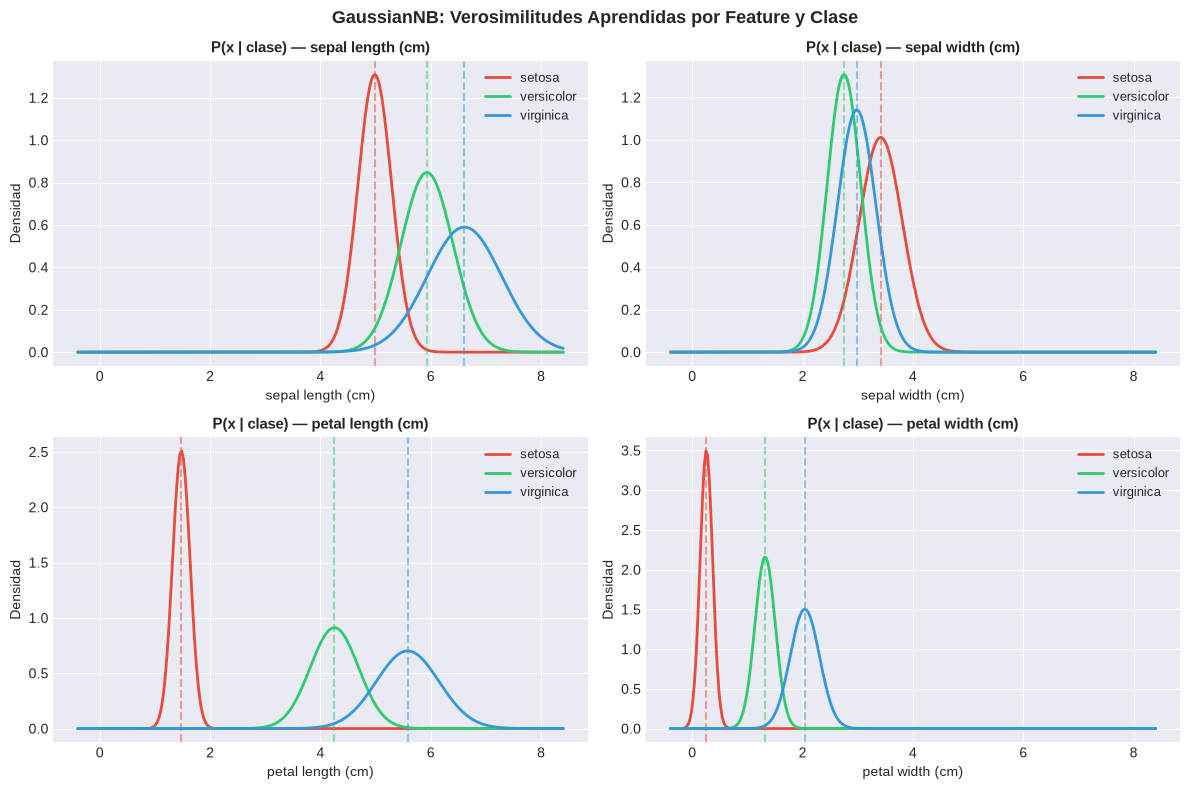

In [20]:
# =============================================================================
# VISUALIZACIÓN 1: Distribuciones Gaussianas aprendidas por clase
# Muestra qué aprendió el modelo sobre cada feature
# =============================================================================
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()
colors = ['#e74c3c', '#2ecc71', '#3498db']
x_range = np.linspace(X.min().min() - 0.5, X.max().max() + 0.5, 300)

for feat_idx, (ax, feat_name) in enumerate(zip(axes, iris.feature_names)):
    for cls_idx, cls_name in enumerate(iris.target_names):
        mu  = gnb.theta_[cls_idx, feat_idx]
        std = np.sqrt(gnb.var_[cls_idx, feat_idx])
        # Calcular densidad gaussiana manualmente para mostrar qué aprendió el modelo
        pdf = (1 / (std * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x_range - mu) / std) ** 2)
        ax.plot(x_range, pdf, color=colors[cls_idx], lw=2, label=cls_name)
        ax.axvline(mu, color=colors[cls_idx], linestyle='--', alpha=0.5)
    ax.set_title(f'P(x | clase) — {feat_name}', fontsize=11, fontweight='bold')
    ax.set_xlabel(feat_name); ax.set_ylabel('Densidad')
    ax.legend(fontsize=9)

plt.suptitle('GaussianNB: Verosimilitudes Aprendidas por Feature y Clase',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

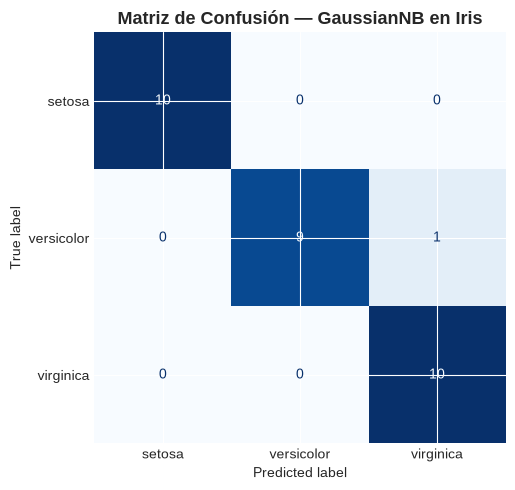

In [21]:
# =============================================================================
# VISUALIZACIÓN 2: Matriz de Confusión
# =============================================================================
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=iris.target_names).plot(
    ax=ax, colorbar=False, cmap='Blues'
)
ax.set_title('Matriz de Confusión — GaussianNB en Iris', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 8. Caso Avanzado — Breast Cancer con Calibración de Probabilidades

In [22]:
# =============================================================================
# BREAST CANCER — GaussianNB + Calibración de Probabilidades
# Problema: NB produce probabilidades extremas (muy cercanas a 0 o 1).
# Solución: CalibratedClassifierCV con método 'isotonic' o 'sigmoid'.
# =============================================================================
bc = load_breast_cancer(as_frame=True)
X_bc, y_bc = bc.data, bc.target

X_tr, X_te, y_tr, y_te = train_test_split(
    X_bc, y_bc, test_size=0.2, random_state=SEED, stratify=y_bc
)

# Modelo base sin calibrar
gnb_base = GaussianNB()
gnb_base.fit(X_tr, y_tr)

# Modelo calibrado con isotonic regression (más flexible, necesita más datos)
gnb_calib = CalibratedClassifierCV(GaussianNB(), method='isotonic', cv=5)
gnb_calib.fit(X_tr, y_tr)

for name, model in [('GaussianNB (sin calibrar)', gnb_base),
                     ('GaussianNB (calibrado)',    gnb_calib)]:
    yp   = model.predict(X_te)
    yprb = model.predict_proba(X_te)[:, 1]
    print(f'{name}')
    print(f'  Accuracy : {accuracy_score(y_te, yp):.4f}')
    print(f'  ROC-AUC  : {roc_auc_score(y_te, yprb):.4f}')
    print(f'  Log-loss : {log_loss(y_te, yprb):.4f}')
    print()

GaussianNB (sin calibrar)
  Accuracy : 0.9386
  ROC-AUC  : 0.9878
  Log-loss : 0.3713

GaussianNB (calibrado)
  Accuracy : 0.9298
  ROC-AUC  : 0.9873
  Log-loss : 0.1548



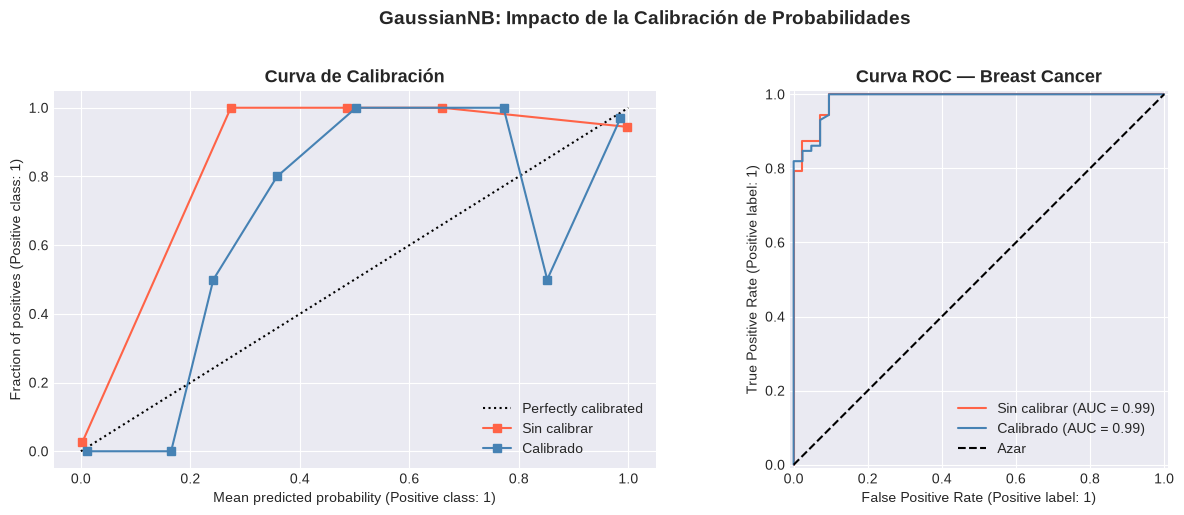

In [23]:
# =============================================================================
# VISUALIZACIÓN 3: Calibration Curve — ¿Qué tan confiables son las probabilidades?
# Una curva perfectamente calibrada sigue la diagonal (y_pred ≈ y_real).
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Calibration Curves ---
for name, model, color in [('Sin calibrar', gnb_base, 'tomato'),
                             ('Calibrado',    gnb_calib, 'steelblue')]:
    CalibrationDisplay.from_estimator(
        model, X_te, y_te, n_bins=10, ax=axes[0],
        name=name, color=color
    )
axes[0].set_title('Curva de Calibración', fontsize=13, fontweight='bold')
axes[0].legend()

# --- ROC Curves ---
# for name, model, color in [('Sin calibrar', gnb_base, 'tomato'),
#                              ('Calibrado',    gnb_calib, 'steelblue')]:
#     RocCurveDisplay.from_estimator(model, X_te, y_te, ax=axes[1], name=name, color=color)

for name, model, color in [('Sin calibrar', gnb_base, 'tomato'),
                             ('Calibrado',    gnb_calib, 'steelblue')]:
    RocCurveDisplay.from_estimator(model, X_te, y_te, ax=axes[1], name=name, curve_kwargs={'color': color})


axes[1].plot([0,1],[0,1],'k--', label='Azar')
axes[1].set_title('Curva ROC — Breast Cancer', fontsize=13, fontweight='bold')
axes[1].legend()


plt.suptitle('GaussianNB: Impacto de la Calibración de Probabilidades',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## 9. Comparativa de Variantes de Naive Bayes

In [24]:
# =============================================================================
# COMPARATIVA: GaussianNB vs BernoulliNB vs MultinomialNB
# Para Breast Cancer (features continuas → binarizamos para Bernoulli y Multinomial)
# =============================================================================
from sklearn.preprocessing import Binarizer, MinMaxScaler

results_var = {}

# GaussianNB: pensado para features continuas — el más apropiado aquí
gnb_pipe = Pipeline([('scaler', StandardScaler()), ('nb', GaussianNB())])
scores = cross_val_score(gnb_pipe, X_bc, y_bc, cv=5, scoring='roc_auc')
results_var['GaussianNB'] = scores

# BernoulliNB: features binarizadas (0/1)
bnb_pipe = Pipeline([('bin', Binarizer(threshold=0.0)), ('nb', BernoulliNB())])
scores = cross_val_score(bnb_pipe, X_bc, y_bc, cv=5, scoring='roc_auc')
results_var['BernoulliNB'] = scores

# MultinomialNB: requiere features no negativas (escalar a [0,1])
mnb_pipe = Pipeline([('scaler', MinMaxScaler()), ('nb', MultinomialNB())])
scores = cross_val_score(mnb_pipe, X_bc, y_bc, cv=5, scoring='roc_auc')
results_var['MultinomialNB'] = scores

# ComplementNB: igual que Multinomial pero más robusto a clases desbalanceadas
cnb_pipe = Pipeline([('scaler', MinMaxScaler()), ('nb', ComplementNB())])
scores = cross_val_score(cnb_pipe, X_bc, y_bc, cv=5, scoring='roc_auc')
results_var['ComplementNB'] = scores

print('Variante             ROC-AUC (5-fold CV)')
print('-' * 42)
for name, sc in results_var.items():
    print(f'{name:<20s}  {sc.mean():.4f} ± {sc.std():.4f}')

Variante             ROC-AUC (5-fold CV)
------------------------------------------
GaussianNB            0.9855 ± 0.0103
BernoulliNB           0.5183 ± 0.0096
MultinomialNB         0.9280 ± 0.0289
ComplementNB          0.9280 ± 0.0289


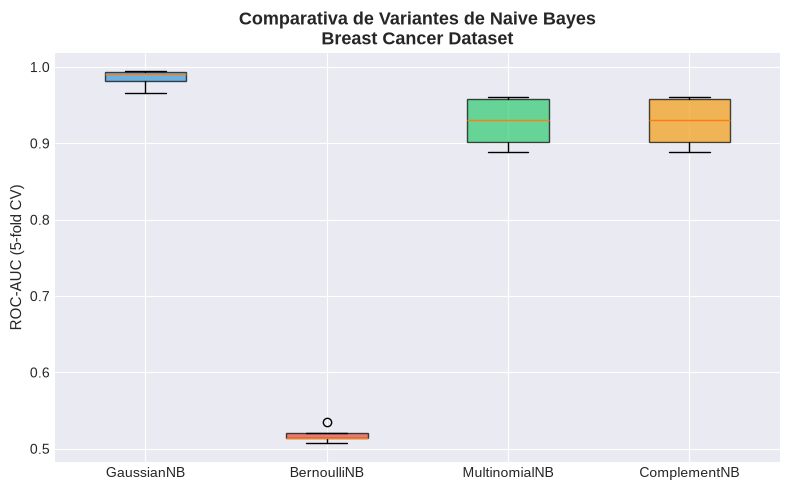

In [25]:
# =============================================================================
# VISUALIZACIÓN 4: Boxplot comparativo de variantes
# =============================================================================
fig, ax = plt.subplots(figsize=(8, 5))
colors_box = ['#3498db', '#e74c3c', '#2ecc71', '#f39c12']
bp = ax.boxplot(results_var.values(),tick_labels=results_var.keys(),
                patch_artist=True)
for patch, color in zip(bp['boxes'], colors_box):
    patch.set_facecolor(color); patch.set_alpha(0.7)
ax.set_ylabel('ROC-AUC (5-fold CV)', fontsize=11)
ax.set_title('Comparativa de Variantes de Naive Bayes\nBreast Cancer Dataset',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 10. Efecto de var_smoothing en GaussianNB

Mejor var_smoothing: 1.00e-12 | ROC-AUC: 0.9855


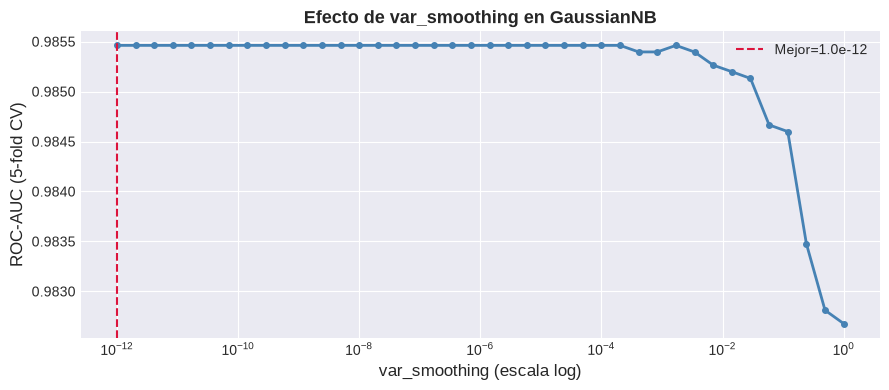

In [26]:
# =============================================================================
# HYPERPARAMETER TUNING: var_smoothing
# Controla cuánta varianza mínima se añade — actúa como regularización.
# =============================================================================
smoothing_values = np.logspace(-12, 0, 40)
cv_scores_smooth = []

for vs in smoothing_values:
    pipe_vs = Pipeline([
        ('scaler', StandardScaler()),
        ('nb', GaussianNB(var_smoothing=vs))
    ])
    sc = cross_val_score(pipe_vs, X_bc, y_bc, cv=5, scoring='roc_auc')
    cv_scores_smooth.append(sc.mean())

best_vs  = smoothing_values[int(np.argmax(cv_scores_smooth))]
print(f'Mejor var_smoothing: {best_vs:.2e} | ROC-AUC: {max(cv_scores_smooth):.4f}')

fig, ax = plt.subplots(figsize=(9, 4))
ax.semilogx(smoothing_values, cv_scores_smooth, 'o-', color='steelblue',
            linewidth=2, markersize=4)
ax.axvline(best_vs, color='crimson', linestyle='--', label=f'Mejor={best_vs:.1e}')
ax.set_xlabel('var_smoothing (escala log)', fontsize=12)
ax.set_ylabel('ROC-AUC (5-fold CV)', fontsize=12)
ax.set_title('Efecto de var_smoothing en GaussianNB', fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

---
## 11. Resumen y Checklist

| Aspecto | Detalle |
|---|---|
| **Tipo** | Probabilístico, generativo |
| **Entrenamiento** | O(n·d) — muy eficiente |
| **Predicción** | O(K·d) — muy rápido |
| **Supuesto clave** | Independencia condicional de features |
| **Fortaleza** | Escala a millones de muestras, texto, datos escasos |
| **Debilidad** | Supuesto de independencia raramente se cumple |

### Guía de selección de variante:

| Variante | Tipo de feature | Caso de uso típico |
|---|---|---|
| **GaussianNB** | Continua | Sensores, señales, tabular numérico |
| **MultinomialNB** | Conteos enteros | Frecuencia de palabras (TF) |
| **BernoulliNB** | Binaria (0/1) | Presencia/ausencia de palabras |
| **ComplementNB** | Conteos | Texto con clases desbalanceadas |

### ✅ Checklist antes de usar Naive Bayes:
- [ ] ¿Elegí la variante correcta para el tipo de mis features?
- [ ] ¿Apliqué `var_smoothing`/`alpha` para evitar probabilidades cero?
- [ ] ¿Calibré las probabilidades si necesito probabilidades confiables?
- [ ] ¿Verifiqué si la independencia de features es una suposición razonable?
- [ ] ¿Consideré `ComplementNB` si mis clases están desbalanceadas?

---
*Próximo notebook: Regresión Logística*